**Note on AI Use:** I selected the project topic and dataset, designed and ran the notebook, and reviewed the results myself. I used Claude (an AI assistant) to help improve code readability, clean up the code, identify and fix coding errors, and generate some code sections when I found them difficult to implement independently. I tested the generated and modified code, checked the outputs, and wrote the analysis and interpretations in my own words.

**Goal.** Forecast next month's rainfall in Ratnapura and compare ensemble methods: bagging (Random Forest), boosting (XGBoost, LightGBM, CatBoost), stacking and voting, and two hybrids (RF + SARIMA, RF + ANN).

**Data.** Open-Meteo historical weather (reanalysis, i.e. modelled data, not station readings), 2010 to 2025, aggregated to monthly values.

In [1]:
!pip install catboost -q

In [2]:
# imports and settings
import warnings
import pickle
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Settings used across the notebook
LATITUDE, LONGITUDE = 6.68, 80.40      # Ratnapura, Sri Lanka
START_DATE, END_DATE = "2010-01-01", "2025-12-31"
TEST_START = "2022-01-01"              # chronological split: train before, test from here
TARGET = "rain_mm"
LAGS = [1, 2, 3, 12]
RANDOM_STATE = 42

## 2. Data: load, check and aggregate to monthly

The data is downloaded from the Open-Meteo archive API. If the download fails, the function falls back to a saved copy (`ratnapura_daily.csv`) when one exists.

In [3]:
# data loading and checking
def load_data():
    """Download daily weather for Ratnapura (Open-Meteo reanalysis)."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min,"
                 "precipitation_sum,wind_speed_10m_max",
        "timezone": "Asia/Colombo",
    }
    try:
        r = requests.get(url, params=params, timeout=60)
        r.raise_for_status()
        df = pd.DataFrame(r.json()["daily"])
        df["time"] = pd.to_datetime(df["time"])
        df = df.set_index("time")
        df.to_csv("ratnapura_daily.csv")
    except requests.RequestException as err:
        print("Download failed:", err)
        print("Trying the saved copy ratnapura_daily.csv ...")
        df = pd.read_csv("ratnapura_daily.csv", index_col="time", parse_dates=True)
    return df


def check_data(df):
    """Basic quality checks: shape, missing values, ranges, date order."""
    print("Shape:", df.shape)
    print("\nMissing values:\n", df.isna().sum())
    print("\nSummary:\n", df.describe().round(2))
    print("\nDates in order:", df.index.is_monotonic_increasing,
          "| duplicate dates:", df.index.duplicated().sum())


def make_monthly(df):
    """Aggregate daily data to monthly values."""
    monthly = pd.DataFrame({
        "rain_mm": df["precipitation_sum"].resample("MS").sum(),
        "temp_mean": df["temperature_2m_mean"].resample("MS").mean(),
        "temp_max": df["temperature_2m_max"].resample("MS").mean(),
        "temp_min": df["temperature_2m_min"].resample("MS").mean(),
        "wind_max": df["wind_speed_10m_max"].resample("MS").mean(),
    })
    return monthly

In [4]:
#  quick check of the data functions
df = load_data()
check_data(df)
monthly = make_monthly(df)
print("\nMonthly shape:", monthly.shape)
monthly.head()

Shape: (5844, 5)

Missing values:
 temperature_2m_mean    0
temperature_2m_max     0
temperature_2m_min     0
precipitation_sum      0
wind_speed_10m_max     0
dtype: int64

Summary:
        temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
count              5844.00             5844.00             5844.00   
mean                 25.75               29.46               23.01   
std                   0.88                1.60                1.13   
min                  20.60               22.40               17.20   
25%                  25.10               28.40               22.40   
50%                  25.70               29.40               23.10   
75%                  26.30               30.40               23.80   
max                  29.40               35.90               26.30   

       precipitation_sum  wind_speed_10m_max  
count            5844.00             5844.00  
mean               11.33               10.84  
std                14.94                4.13

,rain_mm,temp_mean,temp_max,temp_min,wind_max
time,,,,,
2010-01-01,290.5,25.306452,29.287097,21.761290,5.232258
2010-02-01,251.1,25.882143,30.075000,21.957143,5.260714
2010-03-01,229.6,26.577419,30.983871,22.393548,6.796774
2010-04-01,568.9,26.533333,30.213333,23.786667,6.676667
2010-05-01,395.6,26.183871,29.058065,24.358065,10.451613


## 3. Features and chronological split

Only **past** values are used as features (lags and a rolling mean), plus the month encoded as a cycle. The split is by time: train before 2022, test from 2022. A random split would leak future information into training.

In [5]:
# feature engineering and split
def make_features(monthly):
    """Lag features, rolling mean and month encoding. No same-month values are used."""
    data = monthly.copy()

    for col in ["rain_mm", "temp_mean", "wind_max"]:
        for lag in LAGS:
            data[f"{col}_lag{lag}"] = data[col].shift(lag)

    # Rolling mean of the previous 3 months (shift first so the current month is excluded)
    data["rain_roll3"] = data["rain_mm"].shift(1).rolling(3).mean()

    # Month as a cycle so December and January are close together
    m = data.index.month
    data["month_sin"] = np.sin(2 * np.pi * m / 12)
    data["month_cos"] = np.cos(2 * np.pi * m / 12)

    return data.dropna()


def split_data(data):
    """Chronological train/test split."""
    features = [c for c in data.columns
                if "lag" in c or "roll" in c or c.startswith("month_")]
    train = data[data.index < TEST_START]
    test = data[data.index >= TEST_START]
    return train, test, features

In [6]:
# quick check of the feature functions
data = make_features(monthly)
train, test, features = split_data(data)

print("data shape:", data.shape)
print("features:", len(features))
print("train:", len(train), "months,", train.index.min().date(), "to", train.index.max().date())
print("test: ", len(test), "months,", test.index.min().date(), "to", test.index.max().date())

data shape: (180, 20)
features: 15
train: 132 months, 2011-01-01 to 2021-12-01
test:  48 months, 2022-01-01 to 2025-12-01


## 4. Evaluation metric

In [7]:
# evaluation helper
def evaluate(y_true, y_pred, name):
    """RMSE, MAE and R-squared for one model."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} RMSE={rmse:7.1f}  MAE={mae:7.1f}  R2={r2:6.3f}")
    return {"model": name, "RMSE": rmse, "MAE": mae, "R2": r2}

## 5. Bagging vs boosting, tuning and voting

- **Random Forest** (bagging): many independent trees, predictions averaged.
- **XGBoost, LightGBM, CatBoost** (boosting): trees built one after another, each fixing the previous errors.
- **Tuned Random Forest:** GridSearchCV with a time-ordered cross-validation (`TimeSeriesSplit`), never a random one.
- **Voting ensemble:** average of the four tree models' predictions.

In [8]:
# tree models, tuning and voting
def build_models():
    """One bagging model and three boosting models, with small trees for a small dataset."""
    return {
        "Random Forest": RandomForestRegressor(
            n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
        "XGBoost": XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3,
            subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE),
        "LightGBM": LGBMRegressor(
            n_estimators=300, learning_rate=0.05, num_leaves=8,
            min_child_samples=5, random_state=RANDOM_STATE, verbose=-1),
        "CatBoost": CatBoostRegressor(
            iterations=500, learning_rate=0.05, depth=4,
            random_seed=RANDOM_STATE, verbose=0),
    }


def tune_random_forest(X_train, y_train):
    """Hyperparameter tuning with a time-ordered cross-validation."""
    param_grid = {
        "n_estimators": [200, 500],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 5],
    }
    search = GridSearchCV(
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        param_grid,
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
    )
    search.fit(X_train, y_train)
    return search.best_estimator_, search.best_params_


def build_voting():
    """Voting ensemble: simple average of the four tree models."""
    estimators = [(name, clone(model)) for name, model in build_models().items()]
    return VotingRegressor(estimators)

In [9]:
# quick check of baseline and the four tree models
X_train, y_train = train[features], train[TARGET]
X_test, y_test = test[features], test[TARGET]

evaluate(y_test, test["rain_mm_lag12"], "Seasonal naive")

models = build_models()
for name, model in models.items():
    model.fit(X_train, y_train)
    evaluate(y_test, model.predict(X_test), name)

Seasonal naive               RMSE=  191.4  MAE=  147.5  R2=-0.072
Random Forest                RMSE=  149.2  MAE=  111.3  R2= 0.349
XGBoost                      RMSE=  147.3  MAE=  115.0  R2= 0.365
LightGBM                     RMSE=  158.2  MAE=  124.3  R2= 0.267
CatBoost                     RMSE=  131.8  MAE=  102.7  R2= 0.492


In [10]:
# tuned Random Forest
best_rf, best_params = tune_random_forest(X_train, y_train)
print("Best RF parameters:", best_params)
evaluate(y_test, best_rf.predict(X_test), "Random Forest (tuned)")

Best RF parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 500}
Random Forest (tuned)        RMSE=  149.1  MAE=  111.2  R2= 0.350


{'model': 'Random Forest (tuned)',
 'RMSE': np.float64(149.07469885620526),
 'MAE': 111.20724145915817,
 'R2': 0.34963300355805216}

In [11]:
#  voting ensemble
voting = build_voting().fit(X_train, y_train)
evaluate(y_test, voting.predict(X_test), "Voting (RF+XGB+LGBM+Cat)")

Voting (RF+XGB+LGBM+Cat)     RMSE=  143.4  MAE=  111.8  R2= 0.398


{'model': 'Voting (RF+XGB+LGBM+Cat)',
 'RMSE': np.float64(143.4215358411822),
 'MAE': 111.82701609305832,
 'R2': 0.39802375896840503}

## 6. Hybrid 1: RF + SARIMA (time series)

SARIMA is ARIMA with a seasonal part. I used it instead of plain ARIMA because rainfall repeats every year. SARIMA captures the seasonal pattern, and a Random Forest is trained on SARIMA's **residuals** (what it missed). Final prediction = SARIMA forecast + RF's predicted correction.

SARIMA is fitted on the training period only and then run one step at a time over the test period, so the setup matches the other models, which also use actual past values.

In [12]:
# SARIMA and RF + SARIMA hybrid
def run_sarima_hybrid(train, test, X_train, X_test):
    y_tr = train[TARGET].asfreq("MS")
    y_te = test[TARGET].asfreq("MS")

    sarima = SARIMAX(y_tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)

    # One-step-ahead predictions over train + test, parameters learned on train only
    full = pd.concat([y_tr, y_te])
    fitted = sarima.apply(full).fittedvalues
    sarima_pred = fitted[y_te.index].clip(lower=0)

    # RF learns SARIMA's residuals on the training period (skip the 12-month warm-up)
    resid_train = (y_tr - fitted[y_tr.index]).iloc[12:]
    rf_resid = RandomForestRegressor(
        n_estimators=500, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
    rf_resid.fit(X_train.loc[resid_train.index], resid_train)

    hybrid_pred = (fitted[y_te.index] + rf_resid.predict(X_test)).clip(lower=0)
    return sarima_pred.values, hybrid_pred.values

In [13]:
# quick check of SARIMA and the hybrid
sarima_pred, hybrid_pred = run_sarima_hybrid(train, test, X_train, X_test)
_ = evaluate(y_test, sarima_pred, "SARIMA")
_ = evaluate(y_test, hybrid_pred, "RF + SARIMA (hybrid)")

SARIMA                       RMSE=  138.8  MAE=  110.9  R2= 0.436
RF + SARIMA (hybrid)         RMSE=  143.8  MAE=  114.5  R2= 0.395


## 7. Hybrid 2: RF + ANN (tabular regression)

The ANN needs scaled inputs. Five small networks with different seeds are averaged, because one network on about 130 rows is unstable. The hybrid is a fixed 50/50 average of RF and ANN (the weights are not tuned on the test set, which would leak information).

In [14]:
#  ANN and RF + ANN hybrid
def run_ann(X_train, y_train, X_test):
    scaler = StandardScaler().fit(X_train)          # fit on train only
    Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

    ann_preds = []
    for seed in range(5):
        ann = MLPRegressor(hidden_layer_sizes=(16, 8), alpha=1e-2,
                           max_iter=2000, early_stopping=False, random_state=seed)
        ann.fit(Xtr_s, y_train)
        ann_preds.append(ann.predict(Xte_s))

    return np.clip(np.mean(ann_preds, axis=0), 0, None)


def run_hybrid_rf_ann(rf_pred, ann_pred):
    return 0.5 * np.asarray(rf_pred) + 0.5 * np.asarray(ann_pred)

In [15]:
# quick check of the ANN and the RF + ANN hybrid
ann_pred = run_ann(X_train, y_train, X_test)
rf_pred = models["Random Forest"].predict(X_test)
hybrid_ann = run_hybrid_rf_ann(rf_pred, ann_pred)

_ = evaluate(y_test, ann_pred, "ANN")
_ = evaluate(y_test, hybrid_ann, "RF + ANN (hybrid)")

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


ANN                          RMSE=  127.7  MAE=   98.7  R2= 0.523
RF + ANN (hybrid)            RMSE=  133.2  MAE=  102.8  R2= 0.481


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 8. Stacking

Stacking **learns** how to combine models. The four tree models make predictions, and a small linear model (the meta-learner) learns their weights. The weights are learned from out-of-fold predictions on the training set, using a time-ordered split, so the base models never predict data they were trained on.

In [16]:
# stacking ensemble
def run_stacking(models, X_train, y_train, preds, base_names):
    tscv = TimeSeriesSplit(n_splits=5)

    # Out-of-fold predictions on the training set only
    oof = pd.DataFrame(np.nan, index=X_train.index, columns=base_names)
    for tr_idx, va_idx in tscv.split(X_train):
        for name in base_names:
            m = clone(models[name])
            m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            oof.iloc[va_idx, oof.columns.get_loc(name)] = m.predict(X_train.iloc[va_idx])

    mask = oof.notna().all(axis=1)      # the first chunk is never predicted out-of-fold

    # Meta-learner with non-negative weights, so it acts like a weighted average
    meta = Ridge(alpha=1.0, positive=True)
    meta.fit(oof[mask], y_train[mask])
    weights = {n: round(float(w), 3) for n, w in zip(base_names, meta.coef_)}
    print("Stack weights:", weights, "| intercept:", round(meta.intercept_, 1))

    test_base = np.column_stack([preds[n] for n in base_names])
    return np.clip(meta.predict(test_base), 0, None), weights

In [17]:
#  quick check of stacking
base_names = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
preds_check = {name: models[name].predict(X_test) for name in base_names}

stack_pred, weights = run_stacking(models, X_train, y_train, preds_check, base_names)
_ = evaluate(y_test, stack_pred, "Stacking (RF+XGB+LGBM+Cat)")

Stack weights: {'Random Forest': 0.0, 'XGBoost': 0.0, 'LightGBM': 0.0, 'CatBoost': 0.568} | intercept: 144.2
Stacking (RF+XGB+LGBM+Cat)   RMSE=  139.4  MAE=  111.2  R2= 0.431


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


## 9. Main: run everything

`main()` runs the whole pipeline in order and returns everything needed for the plots, the interpretation and the dashboard.

In [18]:
#  main pipeline
def main():
    # Data
    df = load_data()
    check_data(df)
    monthly = make_monthly(df)
    data = make_features(monthly)
    train, test, features = split_data(data)

    X_train, y_train = train[features], train[TARGET]
    X_test, y_test = test[features], test[TARGET]
    print(f"\nTrain: {len(train)} months ({train.index.min():%Y-%m} to {train.index.max():%Y-%m})")
    print(f"Test:  {len(test)} months ({test.index.min():%Y-%m} to {test.index.max():%Y-%m})\n")

    results, preds = [], {}

    # Baseline: same month last year
    preds["Seasonal naive"] = test["rain_mm_lag12"].values
    results.append(evaluate(y_test, preds["Seasonal naive"], "Seasonal naive"))

    # Bagging and boosting
    models = build_models()
    for name, model in models.items():
        model.fit(X_train, y_train)
        preds[name] = model.predict(X_test)
        results.append(evaluate(y_test, preds[name], name))

    # Tuned Random Forest
    best_rf, best_params = tune_random_forest(X_train, y_train)
    preds["Random Forest (tuned)"] = best_rf.predict(X_test)
    results.append(evaluate(y_test, preds["Random Forest (tuned)"], "Random Forest (tuned)"))
    print("Best RF parameters:", best_params)

    # Voting ensemble
    voting = build_voting().fit(X_train, y_train)
    preds["Voting"] = voting.predict(X_test)
    results.append(evaluate(y_test, preds["Voting"], "Voting (RF+XGB+LGBM+Cat)"))

    # Hybrid 1: SARIMA and RF + SARIMA
    sarima_pred, hybrid_pred = run_sarima_hybrid(train, test, X_train, X_test)
    preds["SARIMA"], preds["RF + SARIMA"] = sarima_pred, hybrid_pred
    results.append(evaluate(y_test, sarima_pred, "SARIMA"))
    results.append(evaluate(y_test, hybrid_pred, "RF + SARIMA (hybrid)"))

    # Hybrid 2: ANN and RF + ANN
    ann_pred = run_ann(X_train, y_train, X_test)
    preds["ANN"] = ann_pred
    preds["RF + ANN"] = run_hybrid_rf_ann(preds["Random Forest"], ann_pred)
    results.append(evaluate(y_test, preds["ANN"], "ANN"))
    results.append(evaluate(y_test, preds["RF + ANN"], "RF + ANN (hybrid)"))

    # Stacking
    base_names = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
    stack_pred, weights = run_stacking(models, X_train, y_train, preds, base_names)
    preds["Stacking"] = stack_pred
    results.append(evaluate(y_test, stack_pred, "Stacking (RF+XGB+LGBM+Cat)"))

    res_df = pd.DataFrame(results).set_index("model").sort_values("RMSE")
    return {"monthly": monthly, "features": features, "models": models,
            "y_test": y_test, "preds": preds, "res_df": res_df, "weights": weights}


ctx = main()

Shape: (5844, 5)

Missing values:
 temperature_2m_mean    0
temperature_2m_max     0
temperature_2m_min     0
precipitation_sum      0
wind_speed_10m_max     0
dtype: int64

Summary:
        temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
count              5844.00             5844.00             5844.00   
mean                 25.75               29.46               23.01   
std                   0.88                1.60                1.13   
min                  20.60               22.40               17.20   
25%                  25.10               28.40               22.40   
50%                  25.70               29.40               23.10   
75%                  26.30               30.40               23.80   
max                  29.40               35.90               26.30   

       precipitation_sum  wind_speed_10m_max  
count            5844.00             5844.00  
mean               11.33               10.84  
std                14.94                4.13

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

ANN                          RMSE=  127.7  MAE=   98.7  R2= 0.523
RF + ANN (hybrid)            RMSE=  133.2  MAE=  102.8  R2= 0.481
Stack weights: {'Random Forest': 0.0, 'XGBoost': 0.0, 'LightGBM': 0.0, 'CatBoost': 0.568} | intercept: 144.2
Stacking (RF+XGB+LGBM+Cat)   RMSE=  139.4  MAE=  111.2  R2= 0.431


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


## 10. Results

,RMSE,MAE,R2
model,,,
ANN,127.729,98.651,0.523
CatBoost,131.780,102.748,0.492
RF + ANN (hybrid),133.231,102.841,0.481
SARIMA,138.793,110.943,0.436
Stacking (RF+XGB+LGBM+Cat),139.421,111.153,0.431
Voting (RF+XGB+LGBM+Cat),143.422,111.827,0.398
RF + SARIMA (hybrid),143.754,114.538,0.395
XGBoost,147.297,115.036,0.365
Random Forest (tuned),149.075,111.207,0.350


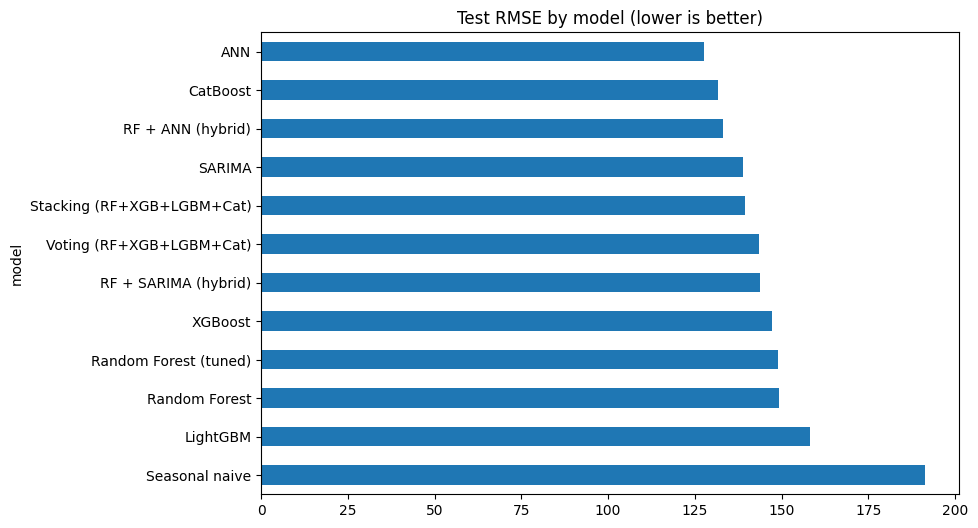

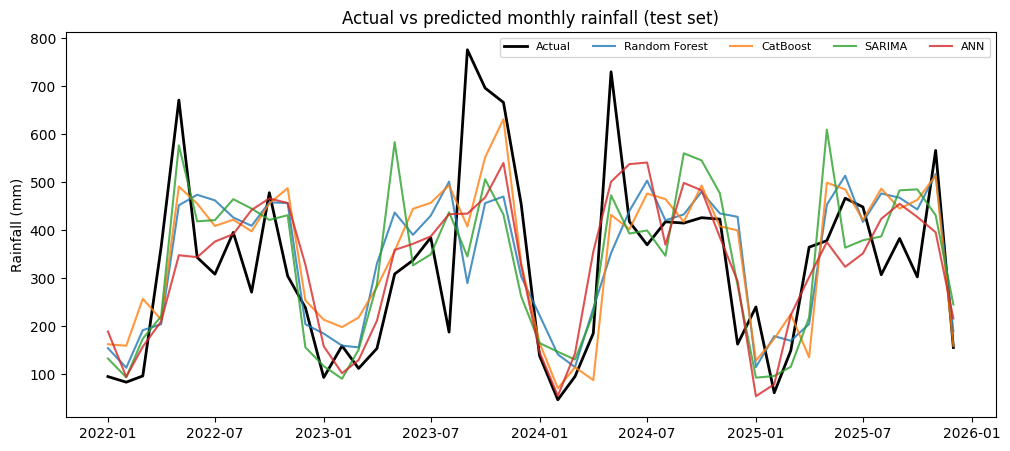

In [19]:
#  results table and plots
res_df, preds, y_test = ctx["res_df"], ctx["preds"], ctx["y_test"]
display(res_df.round(3))

res_df["RMSE"].plot.barh(figsize=(9, 6), title="Test RMSE by model (lower is better)")
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual", color="black", linewidth=2)
for name in ["Random Forest", "CatBoost", "SARIMA", "ANN"]:
    plt.plot(y_test.index, preds[name], label=name, alpha=0.8)
plt.legend(ncol=5, fontsize=8)
plt.title("Actual vs predicted monthly rainfall (test set)")
plt.ylabel("Rainfall (mm)")
plt.show()

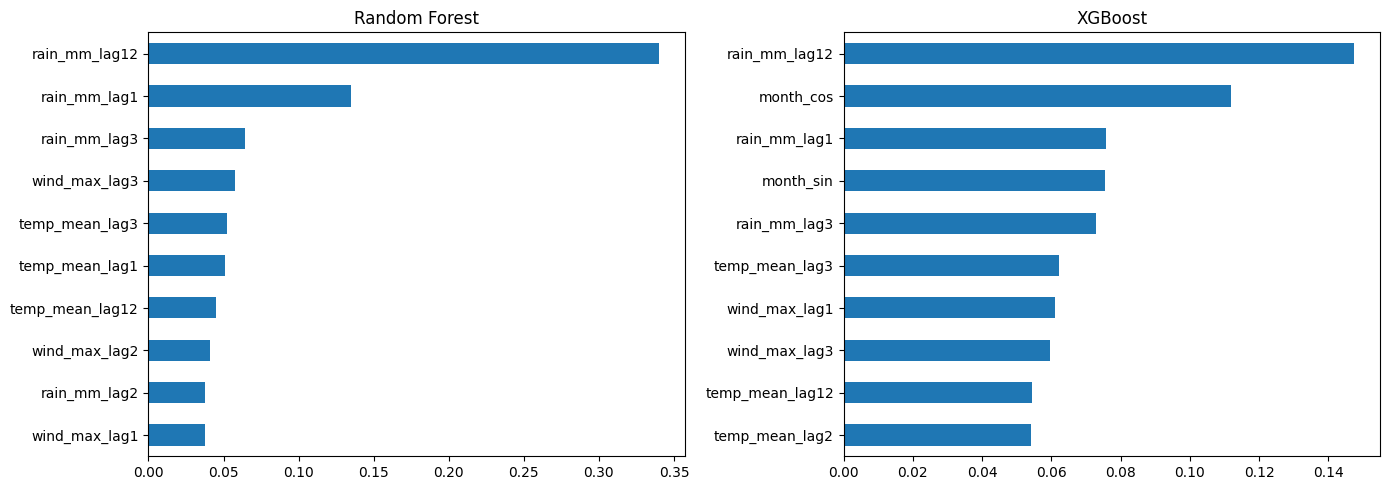

In [20]:
# feature importance (RF and XGBoost)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    imp = pd.Series(ctx["models"][name].feature_importances_,
                    index=ctx["features"]).sort_values()
    imp.tail(10).plot.barh(ax=ax, title=name)
plt.tight_layout()
plt.show()

## 11. Interpretation

**Overall.** All 11 models beat the seasonal naive baseline (RMSE 191.4, R² -0.07), so each learned something beyond "same month last year". The best model was the ANN (RMSE 127.7, R² 0.52), followed by CatBoost (131.8). Monthly rainfall is noisy, so even the best model explains only about half the variation. The test set has only 48 months, so gaps between neighbouring models are small and I treat them as close, not decisive.

**Bagging vs boosting.** CatBoost (boosting, RMSE 131.8) was the best single tree model. Random Forest (bagging, 149.2), XGBoost (147.3) and LightGBM (158.2) were worse. With about 130 training months, CatBoost's built-in regularisation probably helped it avoid overfitting. So boosting did not beat bagging as a rule; it depended on the implementation.

**Hyperparameter tuning.** Tuning the Random Forest with a time-ordered cross-validation (best: max_depth None, min_samples_leaf 5, n_estimators 500) gave RMSE 149.1, essentially the same as the default Random Forest (149.2). With only about 130 rows there is little for tuning to improve, so the default settings were already near the best this model can do here.

**Voting and stacking.** Voting (RMSE 143.4) beat Random Forest, XGBoost and LightGBM but not CatBoost (131.8). Stacking (139.4) also did not beat CatBoost. The stacking weights show why: the meta-learner gave CatBoost a weight of 0.568 and the other three models 0, so the stack was really a scaled and shifted CatBoost. The four base models are all tree-based and make similar errors, so there is little for a meta-learner to combine, and it learned its weights from only about 100 out-of-fold predictions.

**RF + SARIMA hybrid.** The hybrid (143.8) beat RF alone (149.2) but not SARIMA alone (138.8). SARIMA already captured the seasonal pattern, so the leftover residuals were mostly random noise, and training RF on them added variance. I used SARIMA instead of plain ARIMA because rainfall repeats every year.

**RF + ANN hybrid.** The hybrid (133.2) beat RF alone but not the ANN alone (127.7). Averaging a stronger and a weaker model gives a result in between.

**Why the ANN did well.** It is an average of 5 small networks, which reduces variance like bagging does. Rainfall also follows a smooth yearly cycle, which suits a smooth model, while trees approximate it with steps. These reasons are likely, not proven, and the result may not hold on a larger dataset.

**Feature importance.** In the Random Forest, rain_mm_lag12 (rainfall 12 months earlier) was by far the most important feature, followed by rain_mm_lag1 and rain_mm_lag3. In XGBoost, rain_mm_lag12 was also first, followed by month_cos, rain_mm_lag1 and month_sin. Both models rely on rainfall from a year earlier, which shows the yearly seasonal cycle drives the forecast, and XGBoost also uses the month encoding directly.

**Tabular vs image/text data.** Tree ensembles work very well on small tabular data like this, need little preprocessing and are fast to train. On images and text, deep neural networks usually do better because they learn structure (pixels, word order) that trees cannot see.

**Limitations.** Open-Meteo is reanalysis (modelled) data, not station readings. It is one location, 192 months, and one train/test split; rolling cross-validation would be more robust. Extreme events such as the 2016 floods cannot be predicted from lagged values. The ANN hit its iteration limit (ConvergenceWarning), so its result comes from the final iteration.

## 12. Save files for the dashboard

The Streamlit dashboard (`app.py`) loads the Random Forest and these files.

In [21]:
# export model and results for the dashboard
def export_for_dashboard(ctx, best_name="Random Forest"):
    print("scikit-learn version:", __import__("sklearn").__version__)   # use this in requirements.txt

    pickle.dump({"model": ctx["models"][best_name], "features": ctx["features"]},
                open("model.pkl", "wb"))
    ctx["monthly"].to_csv("monthly.csv")
    ctx["res_df"].to_csv("results.csv")

    backtest = pd.DataFrame({"actual": ctx["y_test"]})
    for name, p in ctx["preds"].items():
        backtest[name] = p
    backtest.to_csv("backtest.csv")

    files_to_save = ["model.pkl", "monthly.csv", "results.csv", "backtest.csv"]
    try:
        from google.colab import files
        for f in files_to_save:
            files.download(f)
    except ImportError:
        print("Not running in Colab. Files saved in the current folder:", files_to_save)


export_for_dashboard(ctx)

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>